In [1]:
# ============================================================
# Notebook 3: Defenses Against Adversarial Attacks
# We implement and evaluate practical defenses
# ============================================================

import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# Rebuild SimpleCNN
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1   = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2   = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool    = nn.MaxPool2d(2, 2)
        self.relu    = nn.ReLU()
        self.fc1     = nn.Linear(64 * 7 * 7, 128)
        self.fc2     = nn.Linear(128, 10)
        self.dropout = nn.Dropout(0.25)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = x.view(-1, 64 * 7 * 7)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)

# Valid image range.
# Pixels run from 0 (black) to 1 (white). After normalisation those limits
# become X_MIN and X_MAX. Every adversarial image must stay inside them.
MEAN, STD = 0.1307, 0.3081
X_MIN = (0.0 - MEAN) / STD
X_MAX = (1.0 - MEAN) / STD

# Attack strength used throughout this notebook, in pixel units (0-1 scale).
# 0.3 is the standard value used for MNIST in the research literature.
EPSILON = 0.3

# FGSM (same as notebook 2)
def fgsm_attack(model, images, labels, epsilon):
    images = images.clone().detach().requires_grad_(True)
    loss = nn.CrossEntropyLoss()(model(images), labels)
    model.zero_grad()
    loss.backward()
    return torch.clamp(
        images + (epsilon / STD) * images.grad.data.sign(), X_MIN, X_MAX
    ).detach()

# PGD (same as notebook 2). Step size defaults to epsilon / 10.
def pgd_attack(model, images, labels, epsilon, alpha=None, num_steps=40):
    if alpha is None:
        alpha = epsilon / 10
    eps_n, alpha_n = epsilon / STD, alpha / STD
    adv = torch.clamp(
        images + torch.empty_like(images).uniform_(-eps_n, eps_n), X_MIN, X_MAX
    ).detach()
    for _ in range(num_steps):
        adv.requires_grad = True
        loss = nn.CrossEntropyLoss()(model(adv), labels)
        model.zero_grad()
        loss.backward()
        adv = torch.clamp(
            images + torch.clamp(adv + alpha_n * adv.grad.sign() - images,
                                 -eps_n, eps_n), X_MIN, X_MAX
        ).detach()
    return adv

# Load data
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = torchvision.datasets.MNIST(
    root='../data', train=True, download=False, transform=transform
)
test_dataset = torchvision.datasets.MNIST(
    root='../data', train=False, download=False, transform=transform
)
test_loader = torch.utils.data.DataLoader(
    test_dataset, batch_size=64, shuffle=False
)

# The whole training set as one tensor in memory (same values as the
# transform above produces, but much faster to loop over during training)
X_train = train_dataset.data.float().div(255).sub(MEAN).div(STD).unsqueeze(1)
y_train = train_dataset.targets.clone()

# Load the pre-trained baseline model
baseline_model = SimpleCNN()
baseline_model.load_state_dict(
    torch.load('../models/mnist_cnn_baseline.pth', weights_only=True)
)
baseline_model.eval()
print("Baseline model loaded!")

# Helper function to measure accuracy, optionally under attack
def evaluate(model, loader, attack_fn=None, epsilon=EPSILON):
    model.eval()
    torch.manual_seed(0)           # makes PGD's random start repeatable
    correct, total = 0, 0
    for images, labels in loader:
        if attack_fn:
            images = attack_fn(model, images, labels, epsilon)
        with torch.no_grad():
            _, predicted = model(images).max(1)
        correct += predicted.eq(labels).sum().item()
        total   += labels.size(0)
    return 100. * correct / total

# Measure baseline performance
print("Measuring the undefended baseline (PGD takes a few minutes)...")
clean_acc = evaluate(baseline_model, test_loader)
fgsm_acc  = evaluate(baseline_model, test_loader, fgsm_attack)
pgd_acc   = evaluate(baseline_model, test_loader, pgd_attack)
print(f"\nBaseline model (no defense), epsilon = {EPSILON}:")
print(f"  Clean accuracy : {clean_acc:.2f}%")
print(f"  Under FGSM     : {fgsm_acc:.2f}%")
print(f"  Under PGD      : {pgd_acc:.2f}%")
print(f"\nReady to implement defenses!")

Baseline model loaded!
Measuring the undefended baseline (PGD takes a few minutes)...

Baseline model (no defense), epsilon = 0.3:
  Clean accuracy : 99.09%
  Under FGSM     : 12.82%
  Under PGD      : 0.00%

Ready to implement defenses!


In [2]:
# CELL 2 - Defense 1: Adversarial Training
#
# HOW IT WORKS:
# During training, we generate adversarial examples on the fly
# and include them in the training batch alongside clean images.
# The model learns to correctly classify BOTH clean AND attacked images.
#
# We train two versions and compare them:
#   A) FGSM adversarial training (Goodfellow et al. 2015; Kurakin et al. 2017)
#      Fast: one gradient step per batch.
#   B) PGD adversarial training (Madry et al. 2018)
#      Slower: several gradient steps per batch, but trained against the
#      stronger attack.
# A defense must be tested against the STRONGEST attack available, not only
# the one it was trained on. That is why both models are evaluated with PGD.

def adversarial_training(make_adversarial, name, epochs=5, batch_size=64):
    torch.manual_seed(0)
    model = SimpleCNN()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()
    n = len(X_train)

    for epoch in range(epochs):
        correct, total, running_loss, steps = 0, 0, 0.0, 0
        order = torch.randperm(n)

        for i in tqdm(range(0, n, batch_size), desc=f"{name} epoch {epoch+1}/{epochs}"):
            idx = order[i:i + batch_size]
            images, labels = X_train[idx], y_train[idx]

            # --- Step 1: generate adversarial examples against the current model ---
            model.eval()
            adv_images = make_adversarial(model, images, labels)

            # --- Step 2: train on clean and adversarial images, weighted equally ---
            model.train()
            optimizer.zero_grad()
            clean_outputs = model(images)
            loss = 0.5 * criterion(clean_outputs, labels) + \
                   0.5 * criterion(model(adv_images), labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            steps += 1
            correct += clean_outputs.argmax(1).eq(labels).sum().item()
            total   += labels.size(0)

        print(f"Epoch {epoch+1}: Loss={running_loss/steps:.4f}, "
              f"Train Acc={100.*correct/total:.2f}%")

    model.eval()
    return model

print("Defense 1: Adversarial Training")
print("="*50)
print("Model A (FGSM training) takes about 5-10 minutes.")
print("Model B (PGD training) takes about 20-40 minutes. Please be patient.\n")

# A) FGSM adversarial training
fgsm_trained_model = adversarial_training(
    lambda m, x, y: fgsm_attack(m, x, y, EPSILON),
    "FGSM training")

# B) PGD adversarial training (10 steps per batch, step size epsilon / 4)
pgd_trained_model = adversarial_training(
    lambda m, x, y: pgd_attack(m, x, y, EPSILON, alpha=EPSILON / 4, num_steps=10),
    "PGD training")

print("\nEvaluating both models (two PGD runs, a few minutes each)...")
fgsmtr_clean = evaluate(fgsm_trained_model, test_loader)
fgsmtr_fgsm  = evaluate(fgsm_trained_model, test_loader, fgsm_attack)
fgsmtr_pgd   = evaluate(fgsm_trained_model, test_loader, pgd_attack)

pgdtr_clean  = evaluate(pgd_trained_model, test_loader)
pgdtr_fgsm   = evaluate(pgd_trained_model, test_loader, fgsm_attack)
pgdtr_pgd    = evaluate(pgd_trained_model, test_loader, pgd_attack)

print(f"\nResults at epsilon = {EPSILON}:")
print(f"{'Model':<28} {'Clean':>8} {'FGSM':>8} {'PGD':>8}")
print("-" * 55)
print(f"{'Baseline (no defense)':<28} {clean_acc:>7.2f}% {fgsm_acc:>7.2f}% {pgd_acc:>7.2f}%")
print(f"{'A) FGSM adversarial training':<28} {fgsmtr_clean:>7.2f}% {fgsmtr_fgsm:>7.2f}% {fgsmtr_pgd:>7.2f}%")
print(f"{'B) PGD adversarial training':<28} {pgdtr_clean:>7.2f}% {pgdtr_fgsm:>7.2f}% {pgdtr_pgd:>7.2f}%")

# Save both models. The PGD-trained model is the robust one, so it is the
# one that notebooks 4-6 load as "the adversarially trained model".
torch.save(pgd_trained_model.state_dict(),  '../models/mnist_adversarial_trained.pth')
torch.save(fgsm_trained_model.state_dict(), '../models/mnist_fgsm_trained.pth')
print("\nModels saved:")
print("  models/mnist_adversarial_trained.pth  (PGD adversarial training)")
print("  models/mnist_fgsm_trained.pth         (FGSM adversarial training)")

Defense 1: Adversarial Training
Model A (FGSM training) takes about 5-10 minutes.
Model B (PGD training) takes about 20-40 minutes. Please be patient.



FGSM training epoch 1/5: 100%|███████████████████████████████████████████████████████| 938/938 [01:01<00:00, 15.37it/s]


Epoch 1: Loss=0.4135, Train Acc=94.16%


FGSM training epoch 2/5: 100%|███████████████████████████████████████████████████████| 938/938 [01:00<00:00, 15.41it/s]


Epoch 2: Loss=0.1332, Train Acc=97.71%


...

Epoch 3: Loss=0.2504, Train Acc=97.65%


PGD training epoch 4/5: 100%|████████████████████████████████████████████████████████| 938/938 [03:44<00:00,  4.19it/s]


Epoch 4: Loss=0.1964, Train Acc=97.95%


PGD training epoch 5/5: 100%|████████████████████████████████████████████████████████| 938/938 [23:27<00:00,  1.50s/it]


Epoch 5: Loss=0.1709, Train Acc=98.34%

Evaluating both models (two PGD runs, a few minutes each)...

Results at epsilon = 0.3:
Model                           Clean     FGSM      PGD
-------------------------------------------------------
Baseline (no defense)          99.09%   12.82%    0.00%
A) FGSM adversarial training   98.86%   98.70%    0.00%
B) PGD adversarial training    98.53%   94.69%   91.00%

Models saved:
  models/mnist_adversarial_trained.pth  (PGD adversarial training)
  models/mnist_fgsm_trained.pth         (FGSM adversarial training)


Defense 2: Input Preprocessing
(Two more PGD runs, a few minutes each)

No defense     — Clean: 99.09%  FGSM: 12.82%  PGD: 0.00%
Testing Gaussian smoothing...
Gaussian blur  — Clean: 98.76%  FGSM: 38.63%  PGD: 1.35%
Testing bit-depth reduction...
Bit reduction  — Clean: 99.08%  FGSM: 14.69%  PGD: 0.00%


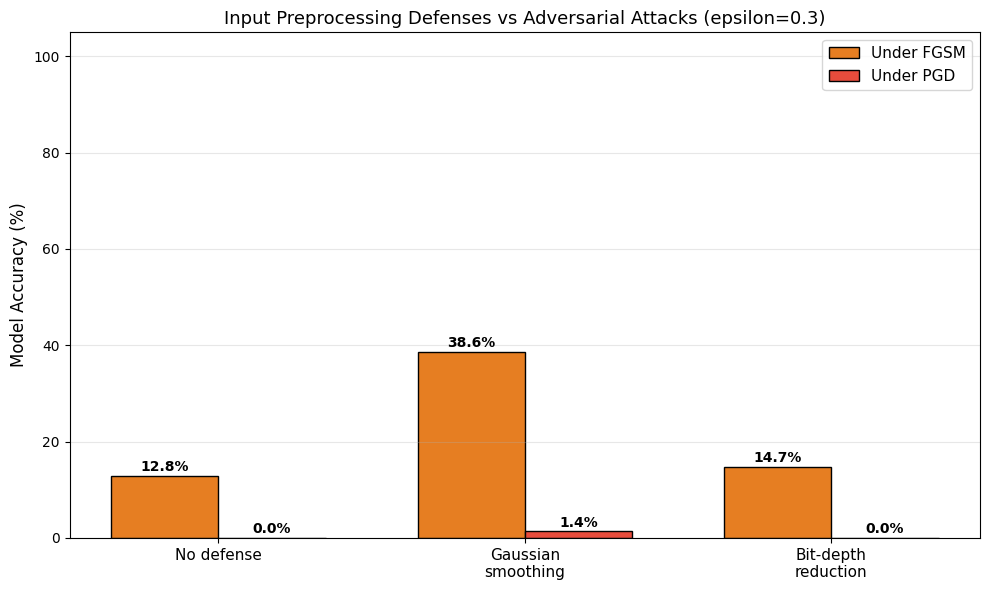


Preprocessing defense results saved!


In [3]:
# CELL 3 - Defense 2: Input Preprocessing
#
# HOW IT WORKS:
# Before feeding an image to the model, we apply a transformation that tries
# to remove adversarial noise while keeping the image recognisable.
# No retraining needed — works on the existing baseline model.
# (Xu et al. 2018 call this family of techniques "feature squeezing".)
#
# Two techniques:
# 1. Gaussian smoothing — blurs the image slightly, smearing out small noise
# 2. Bit-depth reduction — keeps only 16 grey levels, rounding small changes away
#
# The attacker here does NOT know about the preprocessing: the adversarial
# images are made against the plain model and then preprocessed.

import torch.nn.functional as F

def gaussian_smoothing(images):
    """Blur images to remove adversarial noise"""
    sigma = 1.0
    kernel_size = 3
    x = torch.arange(kernel_size).float() - kernel_size // 2
    gauss = torch.exp(-x**2 / (2 * sigma**2))
    gauss = gauss / gauss.sum()
    kernel = (gauss.unsqueeze(0) * gauss.unsqueeze(1))
    kernel = kernel.view(1, 1, kernel_size, kernel_size)
    kernel = kernel.expand(images.shape[1], 1, kernel_size, kernel_size)
    padding = kernel_size // 2
    smoothed = F.conv2d(images, kernel, padding=padding,
                        groups=images.shape[1])
    return smoothed.detach()

def bit_depth_reduction(images, bits=4):
    """Round pixel values to 2^bits grey levels"""
    pixels = (images * STD + MEAN).clamp(0, 1)       # back to 0-1 pixel values
    levels = 2 ** bits - 1
    pixels = torch.round(pixels * levels) / levels
    return ((pixels - MEAN) / STD).detach()           # normalise again

def evaluate_preprocessed(model, loader, attack_fn, epsilon, preprocess_fn):
    """Attack (optional), then preprocess, then predict"""
    model.eval()
    torch.manual_seed(0)
    correct, total = 0, 0
    for images, labels in loader:
        if attack_fn:
            images = attack_fn(model, images, labels, epsilon)
        images = preprocess_fn(images)
        with torch.no_grad():
            _, predicted = model(images).max(1)
        correct += predicted.eq(labels).sum().item()
        total   += labels.size(0)
    return 100. * correct / total

print("Defense 2: Input Preprocessing")
print("="*50)
print("(Two more PGD runs, a few minutes each)\n")

print(f"No defense     — Clean: {clean_acc:.2f}%  FGSM: {fgsm_acc:.2f}%  PGD: {pgd_acc:.2f}%")

# Gaussian smoothing
print("Testing Gaussian smoothing...")
gauss_clean = evaluate_preprocessed(
    baseline_model, test_loader, None, EPSILON, gaussian_smoothing)
gauss_fgsm = evaluate_preprocessed(
    baseline_model, test_loader, fgsm_attack, EPSILON, gaussian_smoothing)
gauss_pgd  = evaluate_preprocessed(
    baseline_model, test_loader, pgd_attack,  EPSILON, gaussian_smoothing)
print(f"Gaussian blur  — Clean: {gauss_clean:.2f}%  FGSM: {gauss_fgsm:.2f}%  PGD: {gauss_pgd:.2f}%")

# Bit-depth reduction
print("Testing bit-depth reduction...")
bits_clean = evaluate_preprocessed(
    baseline_model, test_loader, None, EPSILON, bit_depth_reduction)
bits_fgsm = evaluate_preprocessed(
    baseline_model, test_loader, fgsm_attack, EPSILON, bit_depth_reduction)
bits_pgd  = evaluate_preprocessed(
    baseline_model, test_loader, pgd_attack,  EPSILON, bit_depth_reduction)
print(f"Bit reduction  — Clean: {bits_clean:.2f}%  FGSM: {bits_fgsm:.2f}%  PGD: {bits_pgd:.2f}%")

# Bar chart
fig, ax = plt.subplots(figsize=(10, 6))
defenses  = ['No defense', 'Gaussian\nsmoothing', 'Bit-depth\nreduction']
fgsm_accs = [fgsm_acc, gauss_fgsm, bits_fgsm]
pgd_accs  = [pgd_acc,  gauss_pgd,  bits_pgd]

x     = np.arange(len(defenses))
width = 0.35
bars1 = ax.bar(x - width/2, fgsm_accs, width, label='Under FGSM',
               color='#e67e22', edgecolor='black')
bars2 = ax.bar(x + width/2, pgd_accs,  width, label='Under PGD',
               color='#e74c3c', edgecolor='black')

ax.set_ylabel('Model Accuracy (%)', fontsize=12)
ax.set_title(f'Input Preprocessing Defenses vs Adversarial Attacks (epsilon={EPSILON})',
             fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels(defenses, fontsize=11)
ax.legend(fontsize=11)
ax.set_ylim(0, 105)
ax.grid(axis='y', alpha=0.3)

for bar in list(bars1) + list(bars2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{bar.get_height():.1f}%', ha='center',
            fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('../figures/preprocessing_defenses.png', dpi=150)
plt.show()

# Save results
with open('../results/preprocessing_defense_results.txt', 'w') as f:
    f.write("Input Preprocessing Defense Results\n")
    f.write("="*40 + "\n")
    f.write(f"Epsilon: {EPSILON} (pixel units, 0-1 scale)\n\n")
    f.write(f"No defense    — Clean: {clean_acc:.2f}%  FGSM: {fgsm_acc:.2f}%  PGD: {pgd_acc:.2f}%\n")
    f.write(f"Gaussian blur — Clean: {gauss_clean:.2f}%  FGSM: {gauss_fgsm:.2f}%  PGD: {gauss_pgd:.2f}%\n")
    f.write(f"Bit reduction — Clean: {bits_clean:.2f}%  FGSM: {bits_fgsm:.2f}%  PGD: {bits_pgd:.2f}%\n")

print("\nPreprocessing defense results saved!")

Generating master summary for thesis...

Defense                         Clean   FGSM 0.3    PGD 0.3
-----------------------------------------------------------
Baseline (no defense)          99.09%     12.82%      0.00%
FGSM adversarial training      98.86%     98.70%      0.00%
PGD adversarial training       98.53%     94.69%     91.00%
Gaussian smoothing             98.76%     38.63%      1.35%
Bit-depth reduction            99.08%     14.69%      0.00%


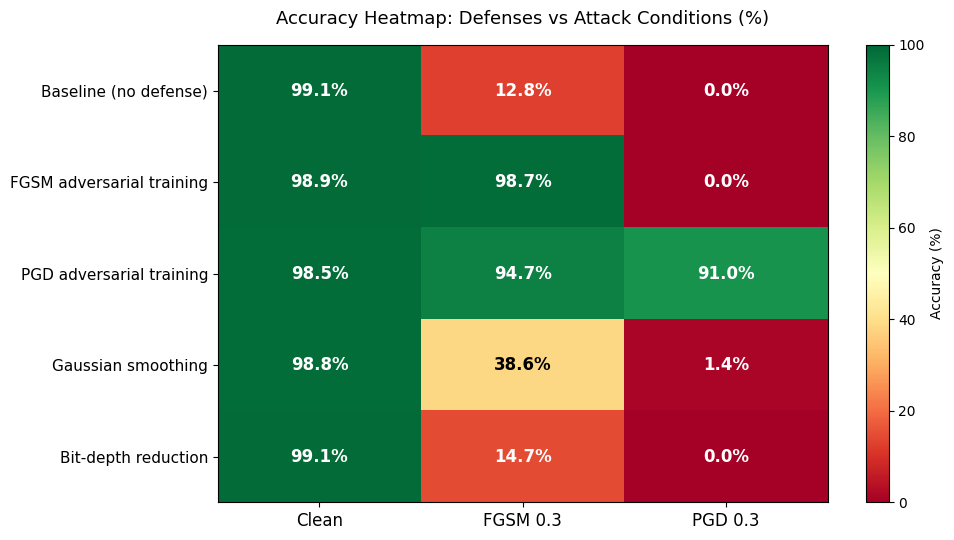

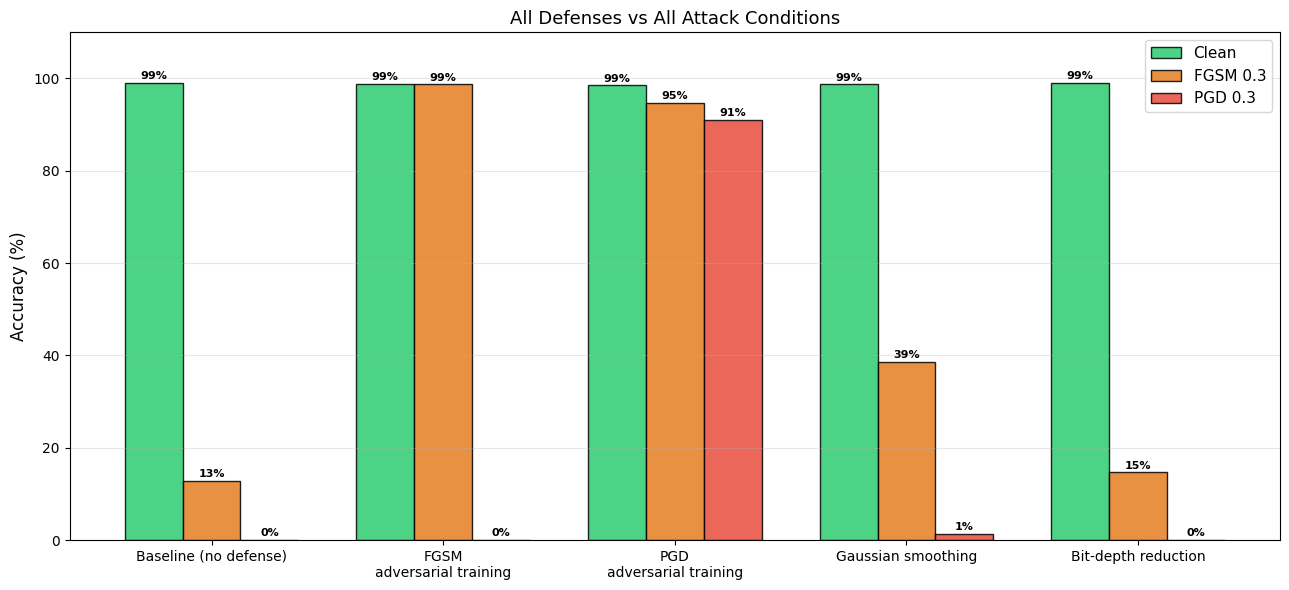


Master results saved to results/MASTER_RESULTS.txt
Most robust defense under PGD: PGD adversarial training (91.00%)

ALL EXPERIMENTS IN THIS NOTEBOOK COMPLETE!

All figures saved to: figures/
All results saved to: results/
All models saved to : models/


In [4]:
# CELL 4 - Master Summary: All Attacks vs All Defenses
# This is the key results table for your thesis chapter.
# Every number below was measured in the cells above.

print("Generating master summary for thesis...\n")

fgsm_col = f"FGSM {EPSILON}"
pgd_col  = f"PGD {EPSILON}"

results = {
    "Baseline (no defense)": {
        "Clean": clean_acc,    fgsm_col: fgsm_acc,    pgd_col: pgd_acc,
    },
    "FGSM adversarial training": {
        "Clean": fgsmtr_clean, fgsm_col: fgsmtr_fgsm, pgd_col: fgsmtr_pgd,
    },
    "PGD adversarial training": {
        "Clean": pgdtr_clean,  fgsm_col: pgdtr_fgsm,  pgd_col: pgdtr_pgd,
    },
    "Gaussian smoothing": {
        "Clean": gauss_clean,  fgsm_col: gauss_fgsm,  pgd_col: gauss_pgd,
    },
    "Bit-depth reduction": {
        "Clean": bits_clean,   fgsm_col: bits_fgsm,   pgd_col: bits_pgd,
    },
}

defenses   = list(results.keys())
conditions = ["Clean", fgsm_col, pgd_col]

# Print results table
print(f"{'Defense':<28} {'Clean':>8} {fgsm_col:>10} {pgd_col:>10}")
print("-" * 59)
for defense, accs in results.items():
    print(f"{defense:<28} {accs['Clean']:>7.2f}%"
          f" {accs[fgsm_col]:>9.2f}%"
          f" {accs[pgd_col]:>9.2f}%")

# Heatmap visualization
fig, ax = plt.subplots(figsize=(10, 5.5))
data = np.array([[results[d][c] for c in conditions] for d in defenses])

im = ax.imshow(data, cmap='RdYlGn', aspect='auto', vmin=0, vmax=100)

ax.set_xticks(range(len(conditions)))
ax.set_yticks(range(len(defenses)))
ax.set_xticklabels(conditions, fontsize=12)
ax.set_yticklabels(defenses, fontsize=11)
ax.set_title("Accuracy Heatmap: Defenses vs Attack Conditions (%)",
             fontsize=13, pad=15)

for i in range(len(defenses)):
    for j in range(len(conditions)):
        val = data[i, j]
        color = 'black' if 30 < val < 80 else 'white'
        ax.text(j, i, f'{val:.1f}%', ha='center', va='center',
                fontsize=12, fontweight='bold', color=color)

plt.colorbar(im, ax=ax, label='Accuracy (%)')
plt.tight_layout()
plt.savefig('../figures/master_summary_heatmap.png', dpi=150)
plt.show()

# Plot grouped bar chart
fig, ax = plt.subplots(figsize=(13, 6))
x     = np.arange(len(defenses))
width = 0.25
colors = ['#2ecc71', '#e67e22', '#e74c3c']

for i, (cond, color) in enumerate(zip(conditions, colors)):
    vals = [results[d][cond] for d in defenses]
    bars = ax.bar(x + (i - 1) * width, vals, width,
                  label=cond, color=color, edgecolor='black', alpha=0.85)
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.8,
                f'{bar.get_height():.0f}%',
                ha='center', fontsize=8, fontweight='bold')

ax.set_ylabel('Accuracy (%)', fontsize=12)
ax.set_title('All Defenses vs All Attack Conditions', fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels([d.replace(" adversarial", "\nadversarial") for d in defenses],
                   fontsize=10)
ax.legend(fontsize=11)
ax.set_ylim(0, 110)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/master_summary_bars.png', dpi=150)
plt.show()

# Which defense is best against the strongest attack?
best_pgd = max(defenses[1:], key=lambda d: results[d][pgd_col])

# Save master results table
with open('../results/MASTER_RESULTS.txt', 'w') as f:
    f.write("MASTER RESULTS TABLE\n")
    f.write("Thesis: Securing Machine Learning Models\n")
    f.write(f"MNIST test set (10,000 images), epsilon = {EPSILON} in pixel units (0-1 scale)\n")
    f.write("="*59 + "\n")
    f.write(f"{'Defense':<28} {'Clean':>8} {fgsm_col:>10} {pgd_col:>10}\n")
    f.write("-"*59 + "\n")
    for defense, accs in results.items():
        f.write(f"{defense:<28} {accs['Clean']:>7.2f}%"
                f" {accs[fgsm_col]:>9.2f}%"
                f" {accs[pgd_col]:>9.2f}%\n")
    f.write(f"\nMost robust defense under PGD: {best_pgd} "
            f"({results[best_pgd][pgd_col]:.2f}%)\n")

print("\nMaster results saved to results/MASTER_RESULTS.txt")
print(f"Most robust defense under PGD: {best_pgd} ({results[best_pgd][pgd_col]:.2f}%)")
print("\n" + "="*50)
print("ALL EXPERIMENTS IN THIS NOTEBOOK COMPLETE!")
print("="*50)
print("\nAll figures saved to: figures/")
print("All results saved to: results/")
print("All models saved to : models/")